### Checkpoint 1

Implement your algorithm to process and annotate the traces of the 20 unipolar electrogram signals, identifying focal activity based on activation patterns and signal morphology.

The algorithm must return the following outputs:

1. **Activation Annotations**: for each of the 20 signals, generate a list of activation times. These activation times correspond to the local minima of the first derivative of the signal, indicating the moments of depolarization at each electrode.
2. **Focal proximity**: assign a score of 1 to the sensor closest to the focal activity and 0 to all others. If the focal activity is within two sensors (up to a specified tolerance), assign 0.5 to each of the two sensors.
This output should be guided by signal morphology: focal activity is expected to correspond to a QS morphology (i.e., a single dominant negative deflection).

Provide your algorithm's implementation in this notebook to annotate the traces of the 20 unipolar signals and identify focal activity based on activation patterns and waveform morphology.



In [77]:
#Imports
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import argrelextrema

In [78]:
# load data
signals = np.load('checkpoint1dataset.npy')

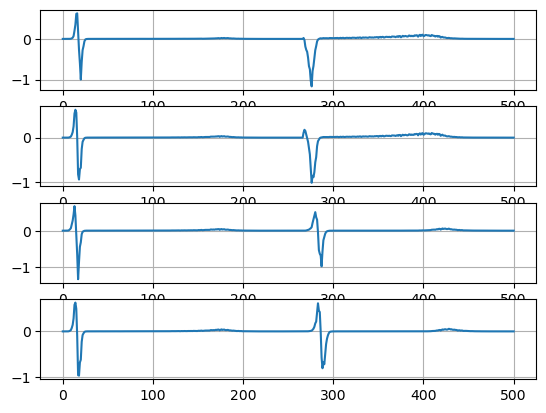

In [79]:
# select event to be display
ind_event = 0

# select a spline (options: 0,1,2,3,4)
ind_spline = 0

# plot signals

plt.figure(1+ind_spline)
countEL = 1
for indS in np.arange(ind_spline*4,(ind_spline+1)*4,1):
    plt.subplot(4,1,countEL)
            
    plt.plot(signals[ind_event,indS,:])
    plt.grid(True)

    countEL = countEL + 1

plt.show()

signals_event = signals[ind_event,:,:]

In [ ]:
def GroupSolutionCP1(signals_event):
    n_sensors = signals_event.shape[0]
    # initialize as requested
    timings = []
    LS = []
    
    min_dist = 100 
    time_tol = 4
    
    first_activations = []
    has_qs = []  # track if sensor has QS morphology
    
    for i in range(n_sensors):
        #calcolo derivata
        ds = np.diff(signals_event[i, :])
        
        #minimi locali
        min_indices = argrelextrema(ds, np.less)[0]
        
        if len(min_indices) > 0:
            #minimi per ampiezza
            depths = ds[min_indices]
            sorted_args = np.argsort(depths) #indici dal più profondo al meno
            
            candidates = min_indices[sorted_args]
            selected = []
            
            for idx in candidates:
                if len(selected) == 0:
                    selected.append(idx)
                elif len(selected) == 1:
                    if abs(idx - selected[0]) >= min_dist:
                        selected.append(idx)
                        break
            
            #salva in ordine temporale
            selected.sort()
            row = [np.nan, np.nan]
            qs_valid = False
            for j, val in enumerate(selected):
                row[j] = val
                if j == 0: 

                    #Definisco finestra temporale precedente all'attivazione
                    window_start = max(0, val - 30)
                    window_end_neg = min(signals_event.shape[1], val + 30)
                    
                    #baseline per riferimento
                    baseline = np.mean(signals_event[i, window_start : window_start + 5])
                    
                    #massima deflection positiva prima dell'attivazione
                    max_pos_deflection = np.max(signals_event[i, window_start : val]) - baseline
                    
                    #minima deflection negativa dopo l'attivazione
                    max_neg_deflection = np.min(signals_event[i, val : window_end_neg]) - baseline
                    
                    #confronto deflessioni per validare complesso QS
                    if max_pos_deflection < 0.1 * abs(max_neg_deflection):
                        qs_valid = True
            first_activations.append(selected[0] if selected else np.inf)
            has_qs.append(qs_valid)
            timings.append(row)
        else:
            timings.append([np.nan, np.nan])
            first_activations.append(np.inf)
            has_qs.append(False)
        
        # append placeholder for LS
        LS.append(0.0)

    #focalita: first find closest sensors, then prioritize QS among them
    if np.any(np.isfinite(first_activations)):
        min_time = np.nanmin(first_activations)
        focus_idxs = [i for i, t in enumerate(first_activations) if t <= min_time + time_tol]
        n_focus = len(focus_idxs)
        
        if n_focus >= 1:
            # sort focus sensors by activation time
            focus_sorted = sorted(focus_idxs, key=lambda i: first_activations[i])
            # find the first two with QS morphology
            qs_candidates = [i for i in focus_sorted if has_qs[i]]
            if qs_candidates:
                sub_tol = 2  # tolerance for "equally close"
                if len(qs_candidates) == 1:
                    LS[qs_candidates[0]] = 1.0
                elif len(qs_candidates) >= 2:
                    time_diff = first_activations[qs_candidates[1]] - first_activations[qs_candidates[0]]
                    if time_diff <= sub_tol:
                        # equally close, assign 0.5 to both
                        LS[qs_candidates[0]] = 0.5
                        LS[qs_candidates[1]] = 0.5
                    else:
                        # first is clearly closer, assign 1.0 to first, 0.5 to second
                        LS[qs_candidates[0]] = 1.0
                        LS[qs_candidates[1]] = 0.5

    return np.array(timings), np.array(LS)

In [81]:
# test it

timings_event, LS_event = GroupSolutionCP1(signals_event)

print("timings_event shape", np.array(timings_event).shape)
print(timings_event)
print("LS_event", LS_event)

timings_event shape (20, 2)
[[ 17 274]
 [ 16 274]
 [ 16 283]
 [ 16 286]
 [ 32 295]
 [ 30 293]
 [ 25 291]
 [ 23 291]
 [ 38 311]
 [ 36 311]
 [ 29 302]
 [ 26 299]
 [ 32 313]
 [ 30 311]
 [ 24 302]
 [ 22 300]
 [ 16 299]
 [ 16 297]
 [ 14 294]
 [ 16 293]]
LS_event [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
